**Problem 3c**

Number proposed: 14244
Number kept: 8564
Fraction kept: 0.6012
Theoretical fraction kept: 0.6000


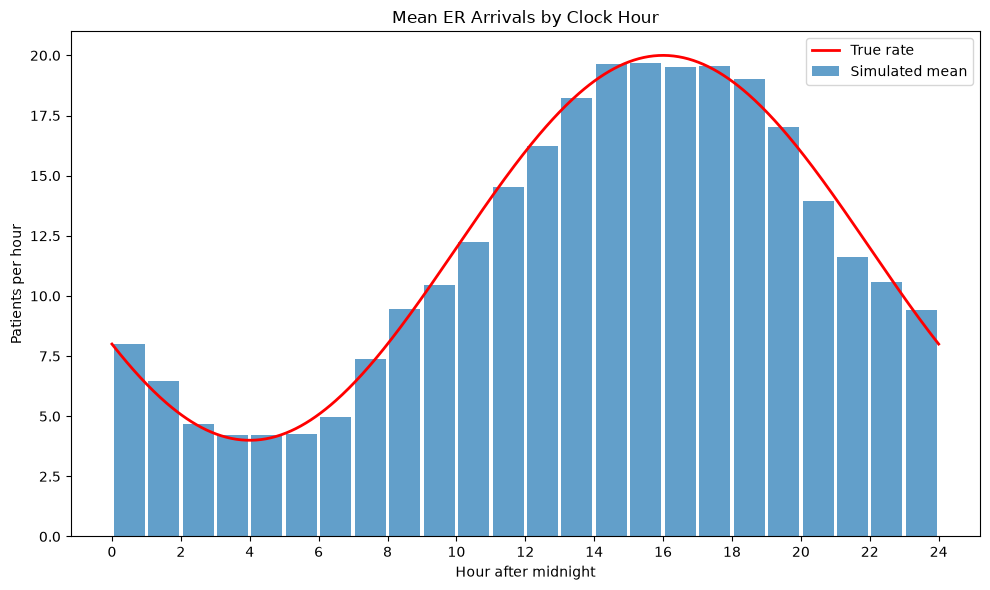


Arrivals from 3 to 4 a.m.
Simulated mean: 4.2333
Simulated variance: 3.0816
Poisson theoretical mean: 4.0910
Poisson theoretical variance: 4.0910

Fitted nonhomogeneous model
a estimate: 11.8945
b estimate: 7.8105
phi estimate: 16.1017
Log-likelihood: 13626.7121

Constant-rate model
Estimated rate: 11.8944
Log-likelihood: 12641.0758

Improvement in log-likelihood: 985.6363


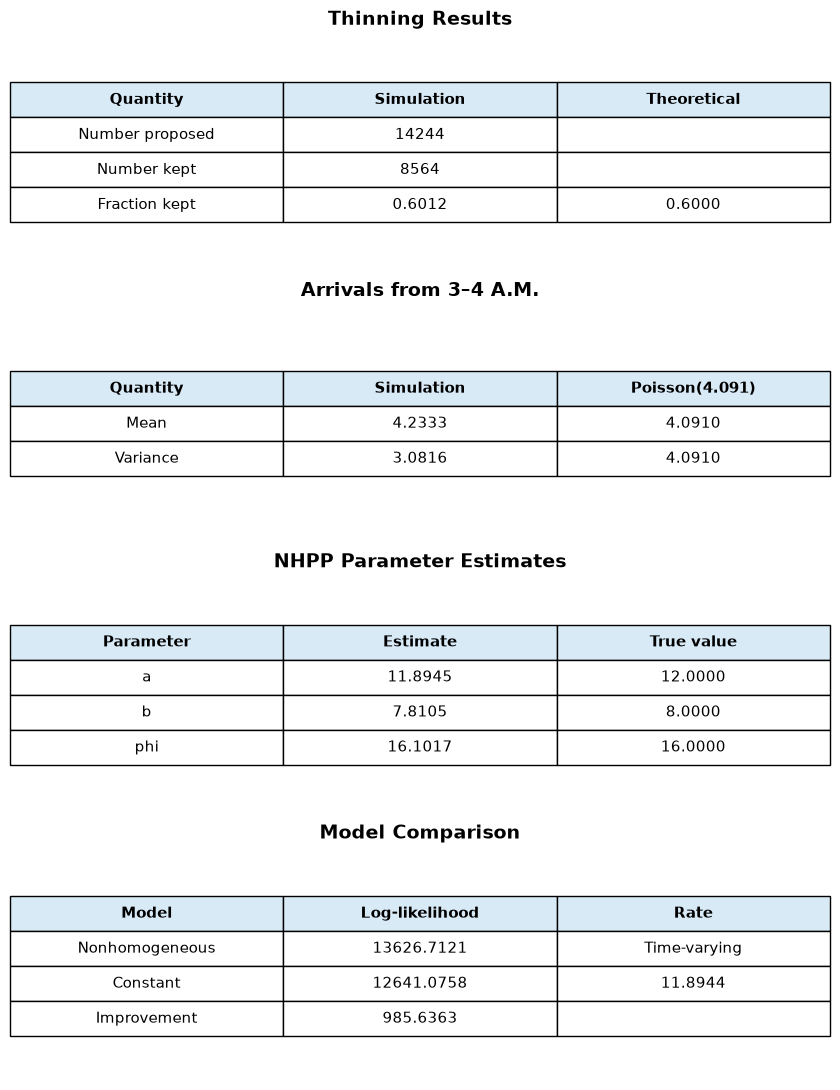

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize


rng = np.random.default_rng(4100)

days = 30
T = 24 * days
max_rate = 20


def rate(t, a=12, b=8, phi=16):
    return a + b * np.cos(np.pi * (t - phi) / 12)


def negative_log_likelihood(parameters, times):
    a, b, phi = parameters
    rates = rate(times, a, b, phi)

    if a <= b or a <= 0 or b < 0:
        return 10 ** 100

    return -(np.sum(np.log(rates)) - a * T)


number_proposed = rng.poisson(max_rate * T)

proposed_times = np.sort(
    rng.uniform(0, T, number_proposed)
)

keep_probabilities = rate(proposed_times) / max_rate

keep = rng.random(number_proposed) < keep_probabilities

arrival_times = proposed_times[keep]

fraction_kept = len(arrival_times) / number_proposed

print(f"Number proposed: {number_proposed}")
print(f"Number kept: {len(arrival_times)}")
print(f"Fraction kept: {fraction_kept:.4f}")
print(f"Theoretical fraction kept: {0.6:.4f}")


clock_hours = np.floor(arrival_times % 24).astype(int)

hourly_counts = np.bincount(
    clock_hours,
    minlength=24
)

hourly_means = hourly_counts / days

hour_grid = np.linspace(0, 24, 500)


#Plot!

plt.figure(figsize=(10, 6))

plt.bar(
    np.arange(24) + 0.5,
    hourly_means,
    width=0.9,
    alpha=0.7,
    label="Simulated mean"
)

plt.plot(
    hour_grid,
    rate(hour_grid),
    color="red",
    linewidth=2,
    label="True rate"
)

plt.xlabel("Hour after midnight")
plt.ylabel("Patients per hour")
plt.title("Mean ER Arrivals by Clock Hour")
plt.xticks(np.arange(0, 25, 2))
plt.legend()
plt.tight_layout()
plt.savefig("3c_hourly_arrivals.png", dpi=300)
plt.show()


day_numbers = np.floor(arrival_times / 24).astype(int)
times_of_day = arrival_times % 24

between_3_and_4 = (
    (times_of_day >= 3)
    & (times_of_day < 4)
)

counts_3_to_4 = np.bincount(
    day_numbers[between_3_and_4],
    minlength=days
)

mean_3_to_4 = np.mean(counts_3_to_4)
variance_3_to_4 = np.var(counts_3_to_4, ddof=1)

print("\nArrivals from 3 to 4 a.m.")
print(f"Simulated mean: {mean_3_to_4:.4f}")
print(f"Simulated variance: {variance_3_to_4:.4f}")
print("Poisson theoretical mean: 4.0910")
print("Poisson theoretical variance: 4.0910")


starting_values = np.array([10, 5, 14])

fit = minimize(
    negative_log_likelihood,
    starting_values,
    args=(arrival_times,),
    method="Nelder-Mead"
)

a_hat, b_hat, phi_hat = fit.x
phi_hat = phi_hat % 24

fitted_log_likelihood = -fit.fun

n = len(arrival_times)
constant_rate = n / T
constant_log_likelihood = (
    n * np.log(constant_rate)
    - constant_rate * T
)

print("\nFitted nonhomogeneous model")
print(f"a estimate: {a_hat:.4f}")
print(f"b estimate: {b_hat:.4f}")
print(f"phi estimate: {phi_hat:.4f}")
print(f"Log-likelihood: {fitted_log_likelihood:.4f}")

print("\nConstant-rate model")
print(f"Estimated rate: {constant_rate:.4f}")
print(f"Log-likelihood: {constant_log_likelihood:.4f}")

print(
    "\nImprovement in log-likelihood: "
    f"{fitted_log_likelihood - constant_log_likelihood:.4f}"
)

fig, axes = plt.subplots(4, 1, figsize=(8.5, 11))

table_data = [
    (
        "Thinning Results",
        ["Quantity", "Simulation", "Theoretical"],
        [
            ["Number proposed", f"{number_proposed}", ""],
            ["Number kept", f"{len(arrival_times)}", ""],
            ["Fraction kept", f"{fraction_kept:.4f}", "0.6000"]
        ]
    ),
    (
        "Arrivals from 3–4 A.M.",
        ["Quantity", "Simulation", "Poisson(4.091)"],
        [
            ["Mean", f"{mean_3_to_4:.4f}", "4.0910"],
            ["Variance", f"{variance_3_to_4:.4f}", "4.0910"]
        ]
    ),
    (
        "NHPP Parameter Estimates",
        ["Parameter", "Estimate", "True value"],
        [
            ["a", f"{a_hat:.4f}", "12.0000"],
            ["b", f"{b_hat:.4f}", "8.0000"],
            ["phi", f"{phi_hat:.4f}", "16.0000"]
        ]
    ),
    (
        "Model Comparison",
        ["Model", "Log-likelihood", "Rate"],
        [
            [
                "Nonhomogeneous",
                f"{fitted_log_likelihood:.4f}",
                "Time-varying"
            ],
            [
                "Constant",
                f"{constant_log_likelihood:.4f}",
                f"{constant_rate:.4f}"
            ],
            [
                "Improvement",
                f"{fitted_log_likelihood - constant_log_likelihood:.4f}",
                ""
            ]
        ]
    )
]

for ax, (title, columns, rows) in zip(axes, table_data):
    ax.axis("off")
    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)

    result_table = ax.table(
        cellText=rows,
        colLabels=columns,
        cellLoc="center",
        loc="center"
    )

    result_table.auto_set_font_size(False)
    result_table.set_fontsize(11)
    result_table.scale(1, 1.7)

    for column in range(len(columns)):
        result_table[(0, column)].set_facecolor("#D9EAF7")
        result_table[(0, column)].set_text_props(fontweight="bold")

plt.tight_layout()
plt.savefig(
    "3c_results_tables.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()